In [188]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from scipy import stats


# Data preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Possible other methods for preprocessing include:
- Removing outliers
- VAE/Bootstrapping
    - Generating new instances from not a lot of data
        - Training data after removing outliers

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [189]:
# verifying data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()
dataset.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


,ID,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,1,144.0,41.0,0,0,0,1,3,3,...,0.517172,0.375126,3.325332,0.002314,3880771.500,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,0,142.0,39.0,1,1,0,0,3,3,...,0.444391,0.444391,3.032144,0.005612,2372009.744,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,1,135.0,31.0,0,0,0,1,2,1,...,0.534549,0.534549,2.485848,0.006752,1540027.421,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,0,12.0,35.0,0,0,0,1,3,3,...,0.506185,0.506185,2.606255,0.003755,6936740.794,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,0,109.0,61.0,1,0,0,0,2,1,...,0.462282,0.462282,2.809279,0.006521,1265399.054,39.621023,0.006585,0.034148,0.001083,0.005626


In [190]:
# Split data into features and outcomes

## Outcomes
dataset_y_clf = dataset['pCR (outcome)']

## Features
dataset_x_all = dataset.drop(['pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis=1)

dataset_x_all

,ID,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,41.0,0,0,0,1,3,3,1,1,...,0.517172,0.375126,3.325332,0.002314,3.880772e+06,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,39.0,1,1,0,0,3,3,1,1,...,0.444391,0.444391,3.032144,0.005612,2.372010e+06,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,31.0,0,0,0,1,2,1,1,0,...,0.534549,0.534549,2.485848,0.006752,1.540027e+06,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,35.0,0,0,0,1,3,3,1,1,...,0.506185,0.506185,2.606255,0.003755,6.936741e+06,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,61.0,1,0,0,0,2,1,1,0,...,0.462282,0.462282,2.809279,0.006521,1.265399e+06,39.621023,0.006585,0.034148,0.001083,0.005626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,TRG002948,58.5,1,0,1,0,3,2,1,1,...,0.476493,0.476493,2.453583,0.003229,2.327038e+06,18.562377,0.013766,0.018042,0.000288,0.012257
396,TRG002954,34.3,0,0,0,1,3,3,1,0,...,0.418382,0.418382,2.995603,0.004243,1.005061e+06,156.627179,0.002228,0.136015,0.022148,0.002098
397,TRG002958,53.3,0,0,0,1,2,1,1,0,...,0.527779,0.527778,1.500000,0.003728,2.132007e+05,0.996746,0.252582,0.007380,0.000037,0.231059
398,TRG002961,68.8,1,0,0,0,3,3,1,1,...,0.313693,0.313693,3.573557,0.001112,2.008034e+07,204.864200,0.001372,0.054063,0.003697,0.001368


## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
- object: ID Column
- float64: Continuous features
- int64: Categorical features

### Handling object datatype
1. Remove object datatype

Remove the ID feature as it is for indexing, instead of a relevant feature

In [191]:
# Handling object datatype
print(dataset_x_all.select_dtypes(object)) # ID Column

print("Before: "+str(dataset_x_all.select_dtypes(object).shape))

dataset_x_all = dataset_x_all.drop("ID",axis=1)
print("After: "+str(dataset_x_all.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but not categorical data (doesn't use classes)


In [192]:
print(dataset_x_all.select_dtypes(np.int64))

print("Before: "+str(dataset_x_all.select_dtypes(np.int64).shape))

# dataset_x_all['Age'] = dataset_x_all['Age'].astype(np.int64)
dataset_x_all['original_shape_VoxelVolume'] = dataset_x_all['original_shape_VoxelVolume'].astype(np.float64)

print("After: "+str(dataset_x_all.select_dtypes(np.int64).shape))

# Save column names of categorical features for later
categorical_names = dataset_x_all.select_dtypes(np.int64).columns
categorical_names

     ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  HistologyType  \
0     0    0     0                1           3              3              1   
1     1    1     0                0           3              3              1   
2     0    0     0                1           2              1              1   
3     0    0     0                1           3              3              1   
4     1    0     0                0           2              1              1   
..   ..  ...   ...              ...         ...            ...            ...   
395   1    0     1                0           3              2              1   
396   0    0     0                1           3              3              1   
397   0    0     0                1           2              1              1   
398   1    0     0                0           3              3              1   
399   1    0     0                0           2              1              1   

     LNStatus  TumourStage 

Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

### Handling float64 datatype
#### Continuous Features

Age is considered a continuous feature as there are continuous values in data
- Considered converting to int, but this would truncate potentially valuable data and lead to Curse of Dimensionality if using One-hot encoding.

In [193]:
# Save column names of continuous features for later
dataset_x_all.select_dtypes(np.float64)
continuous_names = dataset_x_all.select_dtypes(np.float64).columns
continuous_names

Index(['Age', 'original_shape_Elongation', 'original_shape_Flatness',
       'original_shape_LeastAxisLength', 'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter', 'original_shape_MeshVolume',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=108)

## General Preprocessing
1. Null handling (converting '999')
2. Balancing data (Frequency handling)
3. Train-test split #here as following steps would cause data leakage
4. Outlier Removal
5. Data Imputation
6. a - Data Normalisation | b - One-hot Encoding

### 1. Null Handling
Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

In [194]:
# Replace 999 (placeholder) with actual null values
dataset_x_all = dataset_x_all.replace([999], np.nan)

### 2. Balancing Data
We can use stratification when building models to make sure the data is split in the same way as the distribution. We should, therefore, clean up the distribution of data
- Applies for classification as we split based on discrete outcome
- Question: How do we apply to regression?

1. Classification (pCR (outcome))
2. Sampling New Data
3. Truncating Imbalanced Data

##### 1. Classification (pCR (outcome))
Use a histogram to view relative frequencies

pCR (outcome)
0      311
1       84
999      5
Name: count, dtype: int64


<Axes: xlabel='pCR (outcome)', ylabel='count'>

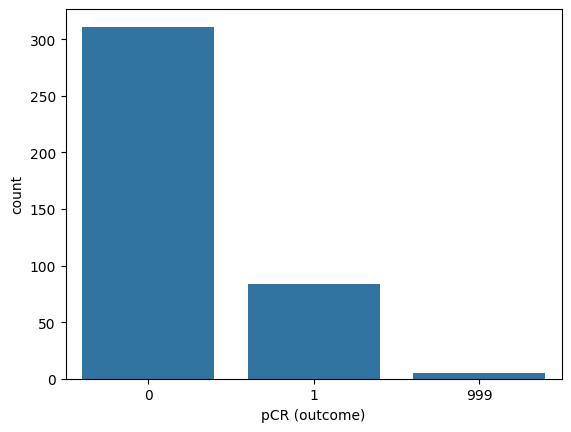

In [195]:
# pCR (outcome) visualisation
print(dataset_y_clf.value_counts())

# sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.countplot(x=dataset_y_clf, data=dataset_x_all)

##### 2. Sampling New Data
Options
- Variational Autoencoder (VAE)
- Generative Adversarial Autoencoder (GAN)
- VAE-GAN? (to mitigate issues with either method)

Generating new data

Variational Autoencoder (VAE)

Generative Adversarial Autoencoder

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.preprocessing import MinMaxScaler
import numpy as np


# Normalize Data to [0, 1] for GAN training (common practice with sigmoid output)
scaler = MinMaxScaler(feature_range=(-1, 1)) # Tanh activation range
X_train_scaled = scaler.fit_transform(dataset_x_all)

In [ ]:
# Building GAN

latent_dim = 64 # Size of random noise vector
data_dim = X_train_scaled.shape[1]

# Generator
def build_generator(latent_dim, data_dim):
    model = tf.keras.Sequential()
    model.add(layers.Dense(128, input_dim=latent_dim))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))
    model.add(layers.Dense(256))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))
    model.add(layers.Dense(data_dim, activation='tanh')) # Output scaled between -1 and 1
    return model

# Discriminator
def build_discriminator(data_dim):
    model = tf.keras.Sequential()
    model.add(layers.Dense(256, input_dim=data_dim))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.4))
    model.add(layers.Dense(128))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.4))
    model.add(layers.Dense(1, activation='sigmoid')) # Output probability
    return model

generator = build_generator(latent_dim, data_dim)
discriminator = build_discriminator(data_dim)

# Compile Discriminator
optimizer = optimizers.Adam(0.0002, 0.5)
discriminator.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# Combined Model (Stack Generator and Discriminator)
# Train Generator to fool Discriminator
discriminator.trainable = False
z = layers.Input(shape=(latent_dim,))
img = generator(z)
validity = discriminator(img)
combined = models.Model(z, validity)
combined.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
# Train GAN
epochs = 500 
batch_size = 3 
# Note: Batch size is tiny because dataset is tiny. 
# In real scenarios, batch_size would be 32 or 64.

valid = np.ones((batch_size, 1))
fake = np.zeros((batch_size, 1))

for epoch in range(epochs):
    # Train Discriminator 
    # Select a random batch of data (here, just the whole dataset essentially)
    idx = np.random.randint(0, X_train_scaled.shape[0], batch_size)
    real_data = X_train_scaled[idx]

    # Generate noise and fake data
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    gen_data = generator.predict(noise, verbose=0)

    # Train
    d_loss_real = discriminator.train_on_batch(real_data, valid)
    d_loss_fake = discriminator.train_on_batch(gen_data, fake)
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

    # Train Generator
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    g_loss = combined.train_on_batch(noise, valid)

    if epoch % 100 == 0:
        print(f"{epoch} [D loss: {d_loss[0]}, acc.: {100*d_loss[1]}%] [G loss: {g_loss}]")

In [ ]:
# Generate New Data
num_new_samples = 220
noise = np.random.normal(0, 1, (num_new_samples, latent_dim))
gen_data_scaled = generator.predict(noise)

# 6. Post-process
gen_data = scaler.inverse_transform(gen_data_scaled)
gen_df = pd.DataFrame(gen_data, columns=dataset_x_all.columns)

# Round categorical columns to nearest integer
for col in categorical_names:
    if col in gen_df.columns:
        gen_df[col] = gen_df[col].round().astype(int)


# Merge with original
final_df = pd.concat([dataset_x_all, gen_df], ignore_index=True)
    
final_df

VAE-GAN

##### 3. Truncating Imbalanced Data
- Includes removing excess data of the dominant class to make an equal balance
- Presents the issue of removing valuable training data

Note: only use if no other options work

### 3. Train-test split
- test_size - (try different ones possibly)
- stratify - train/data will follow distribution of provided categorical outcomes

In [196]:
# Split the X_train into 80% for training data and 20% for test data with stratified splitting to keep the balance of 0 and 1 classes in the training and test sets roughly the same
X_train, X_test, y_train, y_test = train_test_split(dataset_x_all, dataset_y_clf, test_size = 0.2, random_state = 12, stratify = dataset_y_clf)

### 4. Outlier Removal
Options: 
1. Z-Score
2. Interquartile Range

[Other Model-based methods:](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/)

3. Isolation Forest
4. Local Outlier Factor
5. DBSCAN(?)

[Even More Model-based Methods](https://scikit-learn.org/stable/modules/outlier_detection.html#:~:text=OK-,2.7.1.%20Overview%20of%20outlier%20detection%20methods,-%23)

##### Option 1 - Z-score
Removing samples (rows) containing outliers determined using mean and stdev of each feature

In [197]:
# Outlier total
z_scores = np.abs(stats.zscore(X_train))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))


# # Outlier Locations

# for index in outlier_indices:
#     print(index)

Outlier total: 525


In [198]:
# Applying z-score

X_train[(np.abs(stats.zscore(X_train)) < 3).all(axis=1)] # < 3 checks for rows where all features are 3 standard deviations from the mean

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength


Note: Applying Z-score like this is clearly ineffective. This is either due to the presence of null values or as outliers are prevalent in all samples, resulting in an empty dataframe. 

In [199]:
# Apply z score using mean (similar to below IQR) -----------------------

##### Option 2 - Interquartile Range

In [200]:
# Calculating Interquartile Range for all columns
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

In [201]:
# Outputting number of outliers per column
outliers_iqr = ((X_train < (Q1 - 1.5 * IQR)) | (X_train > (Q3 + 1.5 * IQR)))

print("Number of outliers per column: (top 5)")
outliers_col = outliers_iqr.sum()
outliers_col = outliers_col[outliers_col > 0].sort_values(ascending=False)

print(outliers_col.head())

Number of outliers per column: (top 5)
original_ngtdm_Coarseness                       49
original_ngtdm_Strength                         48
HistologyType                                   43
original_glszm_LargeAreaLowGrayLevelEmphasis    42
original_glszm_LargeAreaEmphasis                41
dtype: int64


Note: Using IQR presents a similar issue with z-score as there are likely outliers across many rows. To avoid this, outliers are replaced with the median instead of removing the entire row.

In [202]:
# Handle outliers in columns of continuous features using Interquartile Range of the columns
def outlier_iqr(X_df: pd.DataFrame, continuous_cols: pd.Index):
    
    for col in continuous_cols:
        lower_quartile = X_df[col].quantile(0.25)
        upper_quartile = X_df[col].quantile(0.75)
        iqr = upper_quartile - lower_quartile

        lower_bound = lower_quartile - 1.5 * iqr
        upper_bound = upper_quartile + 1.5 * iqr
        
        # where a value is an outlier
            # replace it with the median
        X_df[col] = np.where((X_df[col] < lower_bound) | (X_df[col] > upper_bound), X_df[col].median(), X_df[col])

outlier_iqr(X_df=X_train, continuous_cols=continuous_names)

In [203]:
# Printing outlier locations
z_scores = np.abs(stats.zscore(X_train))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))

# print("\nOutlier Locations: ")
# for index in outlier_indices:
#     print(index)

Outlier total: 175


##### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. Supposedly better for high dimensions [[reference]](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/#:~:text=IQR%20Method-,3.%20Isolation%20Forest,-Isolation%20Forest%20is)

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

In [204]:
# from sklearn.ensemble import IsolationForest

# iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
# y_pred_iso = iso.fit_predict(X_train)

# X_train["IsoForest_Outlier"] = y_pred_iso
# print(X_train["IsoForest_Outlier"].value_counts())

# plt.figure(figsize=(7, 5))
# sns.scatterplot(x="original_shape_Elongation", y=dataset_y_clf, data=X_train,
#                 hue="IsoForest_Outlier", palette="coolwarm")
# plt.title("Isolation Forest Outlier Detection")
# plt.show()

### 5. Data Imputation
Performed after outlier handling as imputation should perform better with cleaner data, especially for null values

Null values can be removed or imputed, or a combination of both. Consider only removing Gene null values, as other null totals are minimal
- SimpleImputer for imputation by mean/mode/median
- IterativeImputer for model-based imputation

##### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Imputation
3. Imputation of all null values

This class' constructor has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect algorithms (such as IQR and z-score)

Drawback - requires looking at individual feature [distribution](https://medium.com/@silva.f.francis/techniques-for-data-imputation-in-data-science-a-technical-review-85a626b079dd#:~:text=2.1.1%20Mean%2C%20Median%2C%20and%20Mode%20Imputation)

In [205]:
# Viewing features with null values
print("Before Imputation: ")
non_null = dataset_x_all.isnull().sum()
non_null = non_null[non_null > 0]
non_null

Before Imputation: 


PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

Note: The Gene feature should potentially be handled differently, considering the large amount of null data

##### 1. Removal of all null values
Majority of null values are from one feature ('Gene'). This method does not consider whether data with less outliers should be handled differently?

In [206]:
# # Removal (entirely)
# X_train = X_train.dropna()

##### 2. Partial Removal, Partial Imputation
Steps:
1. Removing Gene
2. Imputing other features (format: x|y -> continuous|categorical)

    2.1 Mean|Mode Imputation

    2.2 Mode|Mode Imputation
    
    2.3 Median|Mode Imputation

Impute categorical features using the mode and vary categorical features based on output

Removes the majority of outliers ('Gene'), imputes the rest.

In [207]:
# np.nan is default value to be imputed

imputer_mean = SimpleImputer(strategy='mean')
imputer_mode = SimpleImputer(strategy='most_frequent')
imputer_median = SimpleImputer(strategy = 'median')

In [208]:
## 1. Removing Gene
X_train['Gene'].dropna()


## 2. Imputing other features (format: x|y -> continuous|categorical)
X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

# ### 2.1 Mean|Mode
# X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])  

# ### 2.2 Mode|Mode
# X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])  

### 2.3 Median|Mode
X_train[continuous_names] = imputer_median.fit_transform(X_train[continuous_names])

##### 3. Imputation of all null values

(format: x|y -> continuous|categorical)
1. Imputing using mean|mode
2. Imputing using the median|mode


Added this case as a control for comparison

Mean|Mode Imputation

In [209]:
# X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

Note: The above methods are all very naive, possibly try using more complex imputation.

##### IterativeImputer

1. Nearest neighbour imputation (different scales in features may be punishing)

Allows for models to determine imputation

[This](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation:~:text=of%20IterativeImputer.-,7.4.3.2.%20Multiple%20vs.%20Single%20Imputation,-%23) might be helpful

In [210]:
# Outputting null values: none remaining after imputation

non_null = X_train.isnull().sum()
non_null = non_null[non_null > 0]
non_null

Series([], dtype: int64)

### 6.a Normalisation
Options:
1. MinMax
2. Z-normalisation
3. Vector Normalisation

More research: https://www.geeksforgeeks.org/python/data-normalization-with-pandas/

##### Before Normalisation

<Axes: >

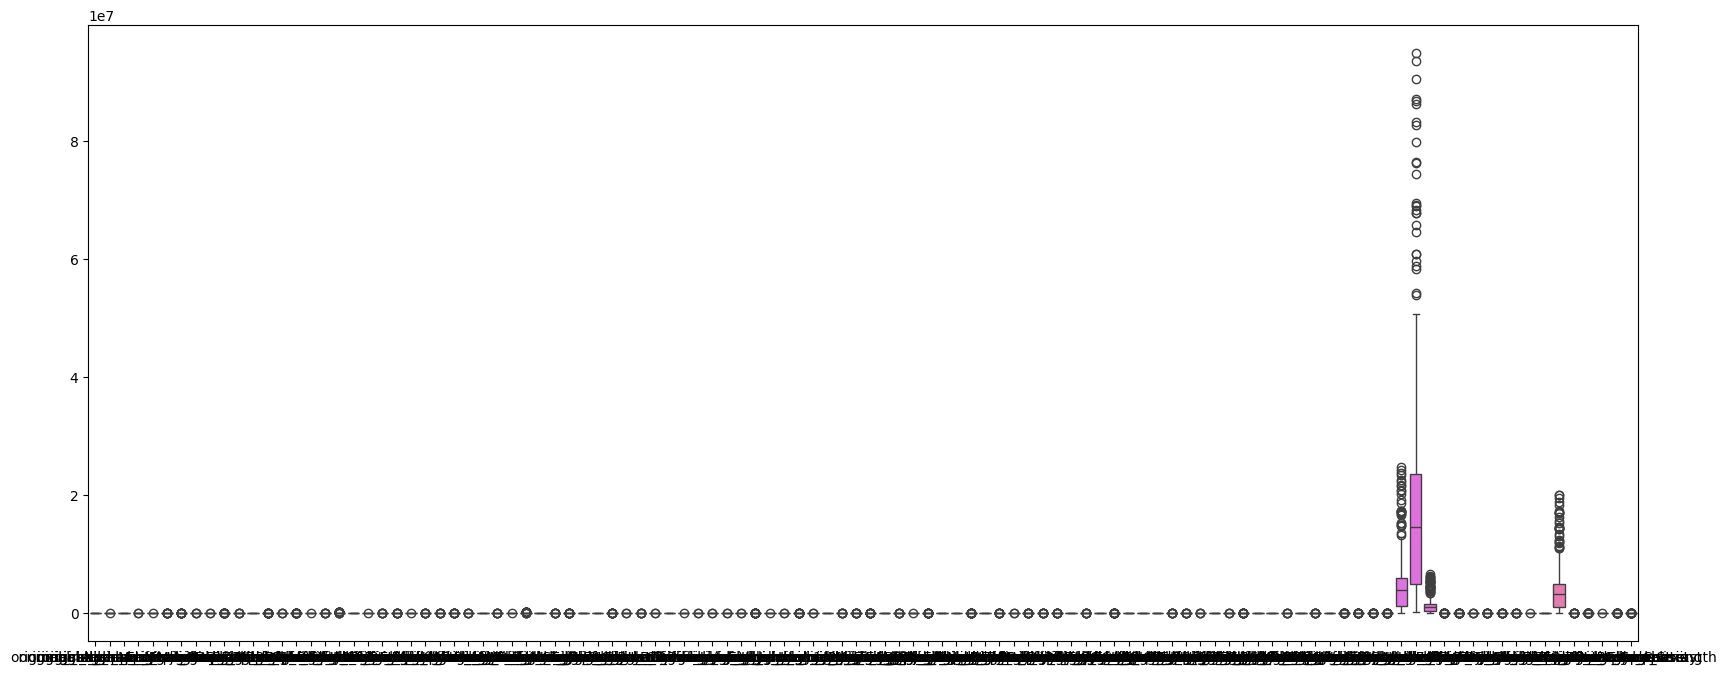

In [211]:
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

##### 1. MinMax
Bounds data to 0-1 range based on the minimum and maximum for each feature. Has the benefit of being numerically robust, especially for distance-based methods like KNN.

<Axes: >

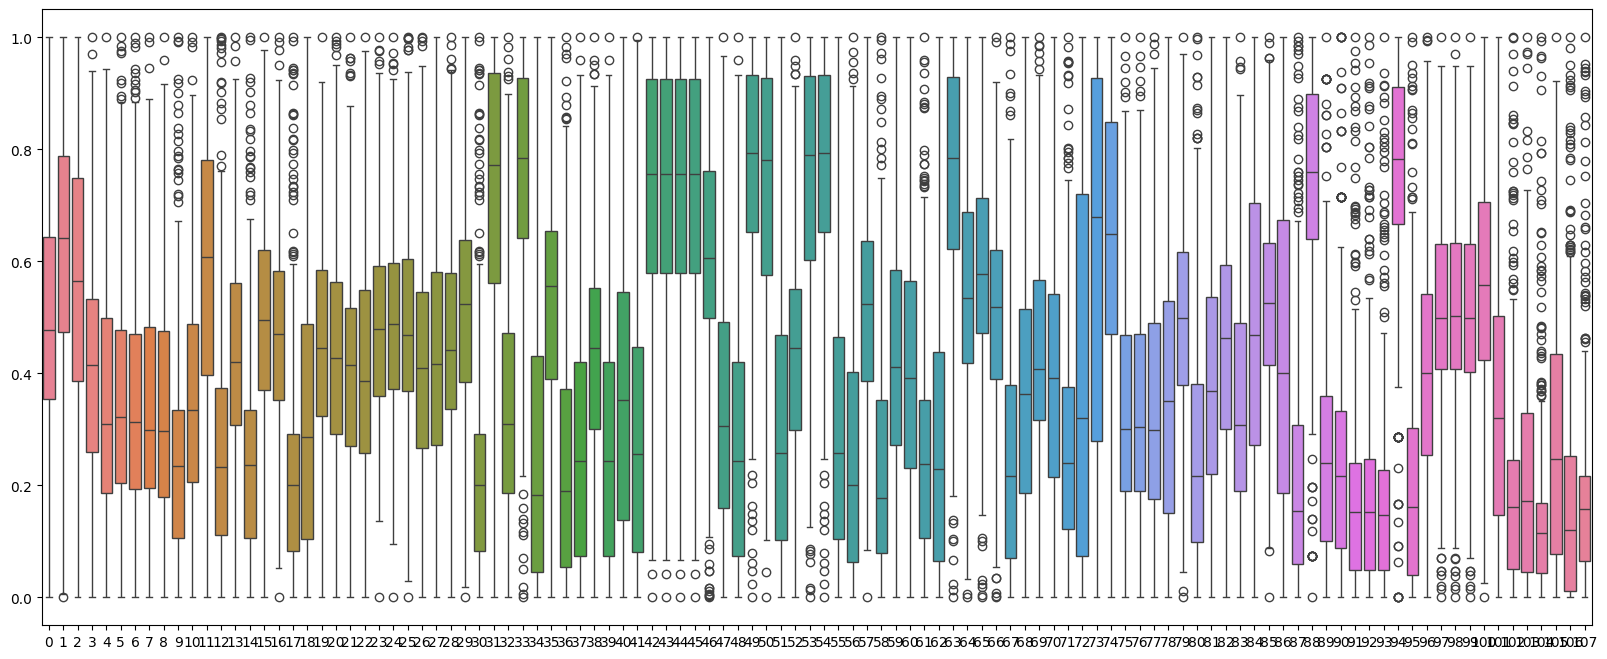

In [212]:
scaler = MinMaxScaler()
# X_train[continuous_names] = scaler.fit_transform(X_train[continuous_names])
# X_train[continuous_names]

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(X_train[continuous_names]),ax=ax)

Note: If this method is to be used, outliers have to be removed as they greatly affect the range

##### 2. Z-normalisation
Currently better in this use case to mitigate outliers

After


<Axes: >

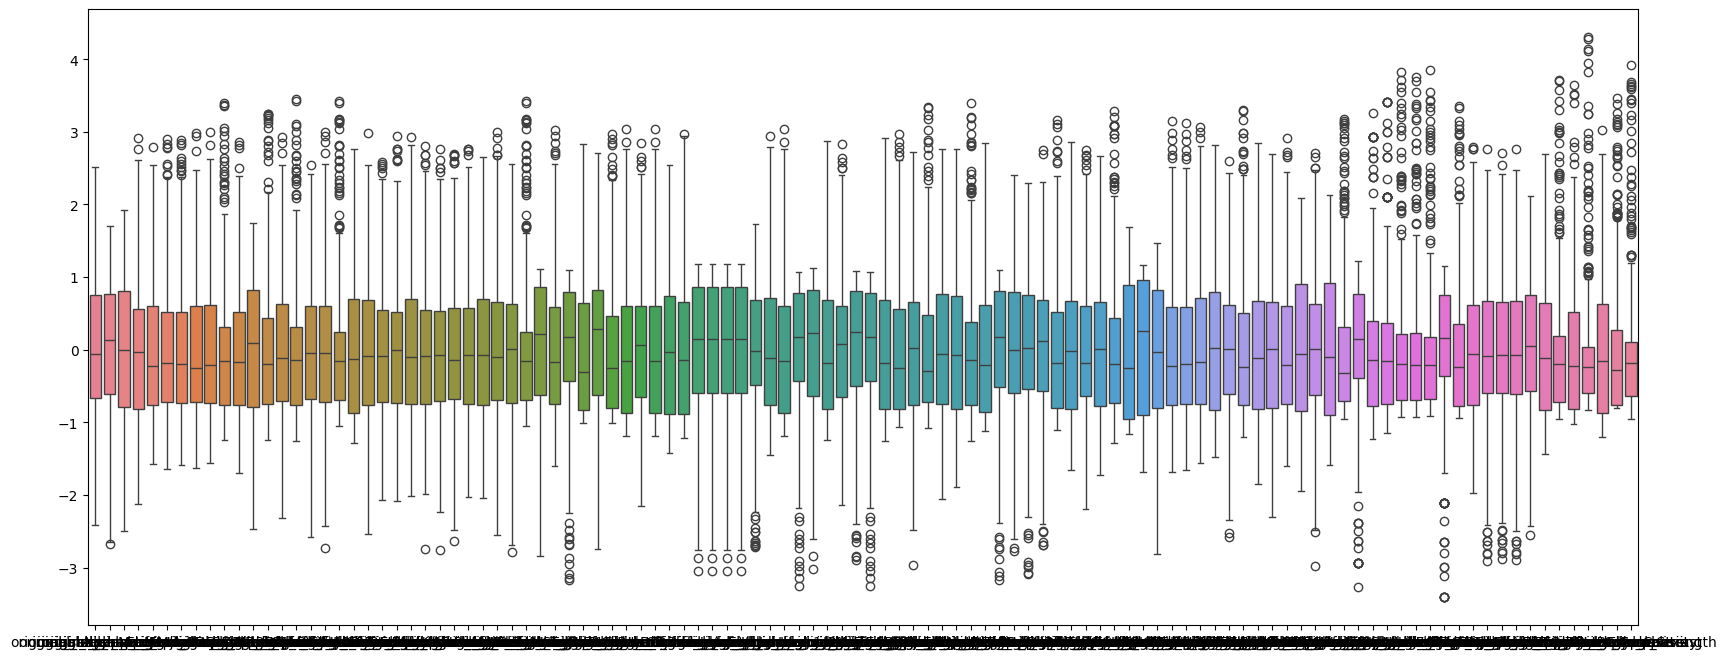

In [213]:
# Apply Z-Score Normalisation to the columns for the continuous features
standard_scaler = StandardScaler()
X_train[continuous_names] = standard_scaler.fit_transform(X_train[continuous_names])

print("After")
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

Note: this method is (currently) more applicable as outliers only affect the individual ranges, not the entire dataset range

### 6.b One-hot Encoding

Parameters:
- drop_first = True: avoids multicollinearity, preventing dependence between one-hot encoded features
- Computationally Expensive - more features means model takes longer to construct

Note: potential issue is that it is typically applied to non numerical data so it can be processed numerically
Note: if making 'Age' categorical, avoid one-hot encoding it so we don't cause curse of dimensionality / make the model more computationally expensive

In [214]:
# from sklearn.preprocessing import OneHotEncoder
# encoder = OneHotEncoder(drop='first')
# encoder.fit(X_train[categorical_names])
# encoder.categories_

In [215]:
# Apply One-Hot Encoding to the columns for the categorical features

X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
# X_train = X_train_encoded

print(f"Before: {X_train.shape}\nAfter: {X_train_encoded.shape}")

Before: (320, 118)
After: (320, 122)


In [216]:
print(categorical_names)
print(X_train_encoded.select_dtypes(bool).columns)

Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')
Index(['ER_1.0', 'PgR_1.0', 'HER2_1.0', 'TrippleNegative_1.0',
       'ChemoGrade_2.0', 'ChemoGrade_3.0', 'Proliferation_2.0',
       'Proliferation_3.0', 'HistologyType_2.0', 'LNStatus_1.0',
       'TumourStage_2.0', 'TumourStage_3.0', 'TumourStage_4.0', 'Gene_1.0'],
      dtype='object')


In [217]:
X_train

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
365,0.216658,1.0,1.0,0.0,0.0,2.0,1.0,1.0,1.0,3.0,...,-0.871570,-0.860645,1.378216,1.255570,-0.752055,-0.360652,-0.148915,-0.460925,-0.566157,0.006132
172,1.409505,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,3.0,...,-0.497915,-0.482041,0.946244,-0.187059,0.893706,-0.220027,-0.752770,1.008087,1.501193,-0.799214
183,-1.550836,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,3.0,...,-0.441930,-0.425347,1.410205,0.522398,-0.622960,-0.269125,-0.237677,-0.585025,-0.622463,-0.124751
299,1.358515,1.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,2.0,...,-0.068133,-0.076214,-2.224874,-0.471307,-0.322513,-0.990492,-0.238181,-1.126528,-0.799307,-0.184271
321,2.003111,1.0,0.0,0.0,0.0,2.0,1.0,2.0,0.0,2.0,...,0.770391,0.802925,0.170272,1.482621,-0.577412,0.846581,-0.585778,0.695150,0.700605,-0.548215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.487266,1.0,0.0,1.0,0.0,2.0,1.0,2.0,1.0,3.0,...,-0.837294,-0.825884,1.592049,0.360829,0.844542,-0.220027,-0.765925,0.648016,0.730689,-0.818790
44,-1.219872,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,2.0,...,0.880837,0.914823,-0.066853,0.773313,0.149000,1.325288,-0.645678,-0.067652,-0.043581,-0.630756
63,-1.769168,1.0,0.0,1.0,0.0,3.0,2.0,2.0,1.0,3.0,...,1.242572,1.132180,-0.053025,-0.035406,2.993087,-0.220027,-0.794910,0.297774,0.873975,-0.851936
388,2.150448,0.0,0.0,0.0,1.0,3.0,2.0,1.0,1.0,3.0,...,0.047531,0.070570,1.129705,0.645735,1.816617,-0.220027,-0.779030,0.109330,-0.025249,-0.834470


# Feature Selection / Dimensionality reduction
### Note: specification says to keep the following features: 'ER', 'HER2' and 'Gene' 

Feature Selection
- Wrapper methods: forward feature selection, recursive feature elimination
- Embedded methods: LASSO, Decision Trees
- Filter based methods: t-tests, chi square, univariate ANOVA, correlation analysis

Dimensionality Reduction
- Includes: PCA, LDA, manifold learning
- Is manifold learning even applicable? 

First do Correlation analysis for visualisation:

In [218]:
# corrMatt = X_train.corr(numeric_only=True)

# # Generate a mask for the upper triangle
# mask = np.zeros_like(corrMatt)
# mask[np.triu_indices_from(mask)] = True

# # Set up the matplotlib figure
# fig, ax = plt.subplots(figsize=(50, 50))

# # Generate a custom diverging colormap
# cmap = sns.diverging_palette(260, 10, as_cmap=True)

# # Draw the heatmap with the mask and correct aspect ratio
# sns.heatmap(corrMatt, vmax=1.2, square=False, cmap=cmap, mask=mask,
# ax=ax, annot=True, fmt='.2g', linewidths=1)

Note: the above needs improving and is currently just a visualisation

### Feature Selection
Feature Selection aims to create a subset of the original features optimal for the model building process. This is split into 3 categories.
- Wrapper Methods
- Embedded Methods
- Filter-based Methods

##### Wrapper Methods
These likely take too long as they iterate through different feature permutations and evaluate them using an evaluation metric. Possibly apply after another method that has already reduced the number of features.

Options:
1. Forward Feature Selection
2. Recursive Feature Elimination



##### 1. Forward Feature Selection

In [219]:
# from sklearn.feature_selection import SequentialFeatureSelector
# from sklearn.neighbors import KNeighborsClassifier

# # Using KNN as the evaluator
# knn = KNeighborsClassifier(n_neighbors=3)
# sfs = SequentialFeatureSelector(knn, n_features_to_select=10, direction='forward')
# sfs.fit(X_train, y_train)

# cols_sfs = X_train.columns[sfs.get_support()]
# print(f"Top 10 Forward Selection Features: {cols_sfs.tolist()}")

##### 2. Recursive Feature Elimination

In [220]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Use a simple estimator
estimator = LogisticRegression(solver='liblinear')
selector_rfe = RFE(estimator, n_features_to_select=10, step=1)
selector_rfe.fit(X_train, y_train)

cols_rfe = X_train.columns[selector_rfe.get_support()]
print(f"Top 10 RFE Features: {cols_rfe.tolist()}")

Top 10 RFE Features: ['ER', 'HER2', 'ChemoGrade', 'Proliferation', 'HistologyType', 'LNStatus', 'Gene', 'original_glcm_ClusterProminence', 'original_glcm_Imc2', 'original_glszm_ZonePercentage']


##### Embedded Methods
Embed Feature Selection into the model process.

Options:
1. LASSO (Regression)
2. Decision Trees / Random Forest

##### 1. LASSO (Regression)


In [221]:
# LASSO
from sklearn.linear_model import Lasso

# Alpha controls regularization strength (higher alpha -> fewer features selected)
lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train) # Using regression target here

# Select features with non-zero weights
lasso_coefs = pd.Series(np.abs(lasso.coef_), index=X_train.columns)
print(f"Top 10 LASSO Features (Regression):\n{lasso_coefs.nlargest(10)}")

Top 10 LASSO Features (Regression):
original_glcm_DifferenceEntropy                    240.575901
original_glcm_DifferenceVariance                   145.977640
original_glcm_Id                                    69.702005
original_glszm_SmallAreaHighGrayLevelEmphasis       62.505793
original_glrlm_HighGrayLevelRunEmphasis             62.457344
original_glszm_SmallAreaEmphasis                    59.386409
original_glrlm_RunLengthNonUniformityNormalized     57.360124
original_firstorder_Mean                            55.964342
original_firstorder_Entropy                         49.448066
original_glcm_SumSquares                            49.303514
dtype: float64


C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.505e+06, tolerance: 3.940e+02
  model = cd_fast.enet_coordinate_descent(


##### 2. Decision Tree / Random Forest

In [222]:
# # Decision Tree/ Random Forest
# from sklearn.ensemble import RandomForestClassifier

# rf = RandomForestClassifier(n_estimators=100, random_state=42)
# rf.fit(X_train, y_train)

# # Get importance
# importances = pd.Series(rf.feature_importances_, index=X_train.columns)
# print(f"Top RF Features:\n{importances.nlargest(10)}")


##### Filter-based Methods
These methods are dependent on the datatypes of features (Xs) and outcomes (ys). Feature datatypes are both categorical and continuous, meaning different methods would have to be applied based on this. The classification outcome, 'pCR (outcome)', is categorical data; meanwhile the regression outcome, 'RelapseFreeSurvival (outcome)', is continuous data.

Note: the above is in theory, as some methods seem to be much more flexible in practice

Note2: theory in this section refers to the lecture content, which is obviously more simplified than in the real world 

Options:

- t-test
- chi-square
- ANOVA
- Correlation Analysis

##### 1. t-test_size

In theory...

Requirements:
- Gaussian Distribution: data is close to gaussian distribution
- Binary Features: data contains binary features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Applicable, features would need to be split

In practice...

##### 2. chi-square 

In theory...

Requirements:
- Categorical Features: dataset contains categorical features
- Categorical Outcome: pCR (outcome) is the categorical outcome

Conclusion: Applicable, features would need to be split

In practice...

Issue: Chi2 uses frequencies which must be positive, causing error

In [223]:
#Chi-square

from sklearn.feature_selection import SelectKBest, chi2

# # Apply Chi2 to Categorical Features vs pCR
# chi2_selector = SelectKBest(chi2, k='all') # Calculate for all, then rank
# chi2_selector.fit(X_train, y_train)

# # Create a DataFrame to view scores
# chi2_scores = pd.DataFrame({
#     'Feature': X_train.columns,
#     'Score': chi2_selector.scores_,
#     'P-Value': chi2_selector.pvalues_
# }).sort_values(by='Score', ascending=False)

# print("Top 10 Chi-Square Features (Categorical):\n", chi2_scores.head(10))

##### 3. ANOVA 

In theory...

Requirements:
- Categorical Features: dataset contains categorical features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outome

Conclusion: Applicable, features would need to be split

In practice...

SelectKBest can use either f_classif or f_regress, allowing it to work for either type of outcome

In [224]:
#ANOVA
from sklearn.feature_selection import f_classif

# Apply ANOVA to Continuous Features vs pCR
anova_selector = SelectKBest(f_classif, k='all')
anova_selector.fit(X_train, y_train)

anova_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'Score': anova_selector.scores_,
    'P-Value': anova_selector.pvalues_
}).sort_values(by='Score', ascending=False)

print("Top 10 ANOVA Features (Continuous):\n", anova_scores.head(10))

Top 10 ANOVA Features (Continuous):
                               Feature      Score   P-Value
10                               Gene  13.181086  0.000003
1                                  ER   7.846654  0.000472
3                                HER2   7.148315  0.000919
2                                 PgR   6.580081  0.001585
117           original_ngtdm_Strength   4.411137  0.012896
34         original_firstorder_Median   4.377557  0.013324
8                            LNStatus   4.145968  0.016695
25   original_firstorder_10Percentile   4.110785  0.017277
116           original_ngtdm_Contrast   4.058109  0.018187
92       original_glrlm_RunPercentage   4.017989  0.018913


##### 4. Correlation Analysis

In theory...

Requirements:
- Continuous Feature: dataset contains continuous features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Not Applicable, outcome is categorical

In practice...

In [225]:
# Correlation analysis

# Calculate Pearson correlation with RelapseFreeSurvival
corr_values = X_train.corrwith(y_train).abs().sort_values(ascending=False)
print("Top 10 Correlated Features (vs RelapseFreeSurvival):\n", corr_values.head(10))

Top 10 Correlated Features (vs RelapseFreeSurvival):
 original_ngtdm_Strength                               0.164535
original_glszm_ZonePercentage                         0.135350
original_shape_MajorAxisLength                        0.117108
original_shape_Maximum3DDiameter                      0.114870
original_shape_Maximum2DDiameterColumn                0.113588
original_shape_Maximum2DDiameterSlice                 0.106582
original_shape_LeastAxisLength                        0.103370
original_ngtdm_Coarseness                             0.099902
original_gldm_SmallDependenceHighGrayLevelEmphasis    0.099126
original_glrlm_GrayLevelNonUniformity                 0.097957
dtype: float64


### Dimensionality Reduction
Reduces the dimension of the data by generating new features from the old ones. This reduces interpretability, as new features are not the same as the old ones, hence we lose some understanding of the dataset

##### VAE (Variational AutoEncoder)
VAE as a feature extraction tool:

Method Overview
- Encoder: Compresses the high-dimensional input data (x) into a probabilistic latent space defined by a mean (μ) and variance (σ).

- Sampling: Uses the "reparameterization trick" to sample a latent vector z from the distribution N(μ,σ).

- Decoder: Attempts to reconstruct the original input from z.

- Dimensionality Reduction: Once trained, discard the decoder and use the Encoder to transform new data into the low-dimensional latent vector z (or simply the mean μ), which serves as the reduced dataset.

In [226]:
# VAE - Variational Auto-Encoder
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

input_dim = X_train.shape[1]
latent_dim = 5 # Target dimensions

# Encoder
encoder_inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(64, activation="relu")(encoder_inputs)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)



##### PCA (Principal Component Analysis)
This unsupervised learning method fits data to a new pair of axes so that it can be split using less features. This is done by calculating the mean (origin of new axes), covariance matrix (ellipse that contains the data), eigenvalues and eigenvectors of the covariance matrix (pair of new axes). 

scikit-learn pca has the following approach:
- n_components is the desired output feature total

In [227]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10)
Xs_pca = pca.fit_transform(X_train)
PCA_df = pd.DataFrame(Xs_pca, columns=['PCA_'+str(i+1) for i in range(Xs_pca.shape[1])])

PCA_df

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,PCA_9,PCA_10
0,-3.177849,-0.219592,8.562393,-1.013738,-2.451464,0.551736,2.977896,-1.292590,-0.153399,-1.531448
1,4.929168,5.914793,2.861735,0.937164,0.026140,1.157827,0.392977,1.500368,0.030032,0.889772
2,-3.568539,2.088863,5.079871,-0.593463,-1.875768,-0.776953,2.655158,-1.959720,-1.248119,-1.723891
3,-5.638098,-5.562137,5.283935,-1.026029,1.527560,0.974034,0.565962,1.299004,-0.222322,-0.757815
4,4.201305,0.419211,1.260556,3.602006,1.133243,-0.210997,-0.222063,-1.566077,0.132185,0.966252
...,...,...,...,...,...,...,...,...,...,...
315,1.849587,7.482807,3.010373,1.986943,-1.970768,0.354778,1.826604,2.131734,0.665543,2.402937
316,0.274747,5.594505,-3.501336,1.906590,0.853247,-1.219218,-0.800118,-2.601335,-1.026974,1.150816
317,3.019763,7.723660,-0.092552,-1.671817,4.407881,-0.809601,-2.516736,-2.163125,0.239772,-0.340063
318,-0.732900,6.751665,0.018240,0.587230,-0.221893,1.289023,-1.278215,-0.823910,1.417600,-0.978894


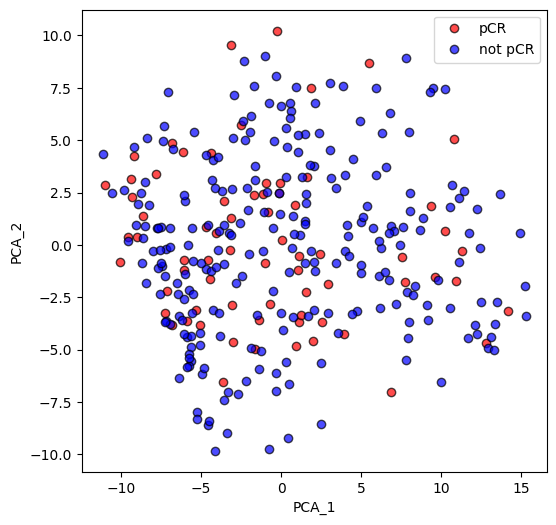

In [228]:
plt.figure(figsize=(6,6))
plt.plot(PCA_df['PCA_1'][dataset_y_clf == 1], PCA_df['PCA_2'][dataset_y_clf == 1], 'ro', alpha = 0.7, markeredgecolor = 'k')
plt.plot(PCA_df['PCA_1'][dataset_y_clf == 0], PCA_df['PCA_2'][dataset_y_clf == 0], 'bo', alpha = 0.7, markeredgecolor = 'k')
plt.xlabel('PCA_1')
plt.ylabel('PCA_2')
plt.legend(['pCR','not pCR'])

In [229]:
X_train

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
365,0.216658,1.0,1.0,0.0,0.0,2.0,1.0,1.0,1.0,3.0,...,-0.871570,-0.860645,1.378216,1.255570,-0.752055,-0.360652,-0.148915,-0.460925,-0.566157,0.006132
172,1.409505,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,3.0,...,-0.497915,-0.482041,0.946244,-0.187059,0.893706,-0.220027,-0.752770,1.008087,1.501193,-0.799214
183,-1.550836,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,3.0,...,-0.441930,-0.425347,1.410205,0.522398,-0.622960,-0.269125,-0.237677,-0.585025,-0.622463,-0.124751
299,1.358515,1.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,2.0,...,-0.068133,-0.076214,-2.224874,-0.471307,-0.322513,-0.990492,-0.238181,-1.126528,-0.799307,-0.184271
321,2.003111,1.0,0.0,0.0,0.0,2.0,1.0,2.0,0.0,2.0,...,0.770391,0.802925,0.170272,1.482621,-0.577412,0.846581,-0.585778,0.695150,0.700605,-0.548215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.487266,1.0,0.0,1.0,0.0,2.0,1.0,2.0,1.0,3.0,...,-0.837294,-0.825884,1.592049,0.360829,0.844542,-0.220027,-0.765925,0.648016,0.730689,-0.818790
44,-1.219872,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,2.0,...,0.880837,0.914823,-0.066853,0.773313,0.149000,1.325288,-0.645678,-0.067652,-0.043581,-0.630756
63,-1.769168,1.0,0.0,1.0,0.0,3.0,2.0,2.0,1.0,3.0,...,1.242572,1.132180,-0.053025,-0.035406,2.993087,-0.220027,-0.794910,0.297774,0.873975,-0.851936
388,2.150448,0.0,0.0,0.0,1.0,3.0,2.0,1.0,1.0,3.0,...,0.047531,0.070570,1.129705,0.645735,1.816617,-0.220027,-0.779030,0.109330,-0.025249,-0.834470


##### LDA (Linear Discriminant Analysis)
This supervised learning method projects data to a new pair of axes that helps split it into different classes. This is done by maximising the variance between data of different classes to separate them, and minimising the mean to keep datapoints within the same class together

In [230]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda = LDA()
lda.fit(X = X_train, y = y_train)

lda.predict(X=[X_train.loc[1]])

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


array([0])

# Machine Learning Method Development

Steps:
1. Sample New Data
2. Test Data Pipeline
3. Machine Learning Methods

### 1. Process Test Data
1. Preprocessing Pipeline
2. Apply Feature Selection


#### 1. Preprocessing Pipeline
- Create Pipeline that transforms test dataset using every desired method following train-test split
- Apply Pipeline

In [235]:
transformers = {
    "imputer_mode": (imputer_mode, categorical_names),
    "imputer_median": (imputer_median, continuous_names),
    "standard_scaler": (standard_scaler, continuous_names)
}

outlier_iqr(X_test, continuous_names) # this is manual so re implement this in any new notebooks
for key, value in transformers.items():
    print(key)
    X_test[value[1]] = value[0].transform(X_test[value[1]])
X_test

imputer_mode
imputer_median
standard_scaler


,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
101,0.039005,0.0,0.0,0.0,1.0,3.0,3.0,1.0,0.0,2.0,...,0.890769,0.924885,0.249956,0.458175,-0.135855,0.276248,-0.486248,-0.147488,-0.256644,-0.443255
334,0.474497,0.0,0.0,0.0,1.0,3.0,3.0,1.0,0.0,1.0,...,-0.055764,-0.034081,-1.121418,0.283773,-0.916209,-0.544503,0.530416,2.186932,0.073898,1.106684
144,-2.693235,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,3.0,...,0.979124,1.014390,-1.305295,-0.891566,-0.366462,-1.011759,-0.469589,-1.168111,-0.801191,-0.427225
107,-0.173529,0.0,1.0,0.0,0.0,2.0,1.0,1.0,1.0,2.0,...,0.217676,0.242950,-0.338764,-0.273899,-0.513819,-0.466863,0.046316,-0.027677,-0.004550,0.453267
130,-1.644371,0.0,0.0,0.0,1.0,3.0,2.0,1.0,1.0,4.0,...,1.473070,1.274304,-0.405190,0.432564,0.645811,0.271919,-0.777945,0.836056,2.025839,-0.823995
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,0.519285,1.0,0.0,1.0,0.0,2.0,1.0,1.0,1.0,3.0,...,-1.313045,-1.308086,0.934017,1.596341,-0.880365,-0.328053,-0.119158,0.665762,0.848695,0.073739
121,-1.562686,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,2.0,...,-1.888014,-1.890400,1.097740,-0.667299,0.330185,0.469850,-0.505887,0.295932,0.642799,-0.432801
211,1.266430,1.0,1.0,1.0,0.0,3.0,1.0,2.0,1.0,3.0,...,-1.180774,-1.173870,0.388982,-0.507141,-0.406333,0.775488,-0.542410,1.677033,3.115970,-0.497743
309,-0.271394,1.0,1.0,1.0,0.0,2.0,1.0,1.0,0.0,2.0,...,-0.830579,-0.819075,1.048671,-0.136597,-0.281874,0.396868,-0.500243,0.571826,0.655869,-0.451012


Note: the above method does not use a pipeline as there is no elegant way to transform specific columns using specific column names in a pipeline

Issues with pipeline:
- ColumnTransformer returns an ndarray (no column names), causing subsequent ColumnTransformers to fail
- Pipeline has to be fitted to new data before calling transform, re-fitting to test data instead of training data (despite above issue)

Evidence of issues is below, commented out code...

In [236]:
# # Preprocess the new data (MUST use the same scaling/imputation fitted objects)
# # Assuming 'new_features' are the preprocessed features ready for the model

# from sklearn.pipeline import make_union, make_pipeline, Pipeline
# from sklearn.preprocessing import FunctionTransformer
# from sklearn.compose import ColumnTransformer

# pipeline = make_pipeline()
# pipeline.__sklearn_is_fitted__
# # outlier removal:
# # outlier_iqr(X_test, continuous_names)

# # data imputation: SimpleImputer median|mode DONE
# ct_imputations = ColumnTransformer([("mode", imputer_mode, categorical_names), ("median", imputer_median, continuous_names)])
# pipeline.steps.append(["imputations", ct_imputations])

# # normalisation: standard scaler
# ct_norm = ColumnTransformer([("z-norm", standard_scaler, continuous_names)], verbose_feature_names_out=True)
# pipeline.steps.append(["z-norm", ct_norm])

# print(pipeline.steps)
# # one-hot encoding
# # pipeline.steps.append(["one-hot", FunctionTransformer(pd.get_dummies, kw_args={"columns":categorical_names, "drop_first":True})])

# # maybe
#     # PCA
#     # LDA

# X_test = pipeline.transform(X_test)
# X_test = pd.DataFrame(X_test)
# X_test

In [237]:
X_train

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
365,0.216658,1.0,1.0,0.0,0.0,2.0,1.0,1.0,1.0,3.0,...,-0.871570,-0.860645,1.378216,1.255570,-0.752055,-0.360652,-0.148915,-0.460925,-0.566157,0.006132
172,1.409505,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,3.0,...,-0.497915,-0.482041,0.946244,-0.187059,0.893706,-0.220027,-0.752770,1.008087,1.501193,-0.799214
183,-1.550836,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,3.0,...,-0.441930,-0.425347,1.410205,0.522398,-0.622960,-0.269125,-0.237677,-0.585025,-0.622463,-0.124751
299,1.358515,1.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,2.0,...,-0.068133,-0.076214,-2.224874,-0.471307,-0.322513,-0.990492,-0.238181,-1.126528,-0.799307,-0.184271
321,2.003111,1.0,0.0,0.0,0.0,2.0,1.0,2.0,0.0,2.0,...,0.770391,0.802925,0.170272,1.482621,-0.577412,0.846581,-0.585778,0.695150,0.700605,-0.548215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.487266,1.0,0.0,1.0,0.0,2.0,1.0,2.0,1.0,3.0,...,-0.837294,-0.825884,1.592049,0.360829,0.844542,-0.220027,-0.765925,0.648016,0.730689,-0.818790
44,-1.219872,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,2.0,...,0.880837,0.914823,-0.066853,0.773313,0.149000,1.325288,-0.645678,-0.067652,-0.043581,-0.630756
63,-1.769168,1.0,0.0,1.0,0.0,3.0,2.0,2.0,1.0,3.0,...,1.242572,1.132180,-0.053025,-0.035406,2.993087,-0.220027,-0.794910,0.297774,0.873975,-0.851936
388,2.150448,0.0,0.0,0.0,1.0,3.0,2.0,1.0,1.0,3.0,...,0.047531,0.070570,1.129705,0.645735,1.816617,-0.220027,-0.779030,0.109330,-0.025249,-0.834470


In [238]:
# Use joblib to export pipeline

In [239]:
# need to preprocess y as well
    # null values

#### 2. Apply Feature Selection

### 2. Machine Learning Models

##### Linear:
- Multivariate Linear Regression
- ~~Logistic Regression~~ (Took over 10 min until interrupted) | Classification
- Naïve Bayes (don't forget different types) | Classification
- K-Nearest Neighbour (KNN) | Classification
- Support Vector Classifier/Regressor

##### Non-Linear:
- Kernel Support Vector Classifier/Regressior
- Decision Tree Classifier/Regressor
- Random Forest Classifier/Regressor

##### Deep Learning Models:
- Multilayer Perceptron Classifier/Regressor
- Convolution Neural Networks -------------------------------------------------

In [240]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier


results = {}

#### Logistic Regression

In [241]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression
log_reg = LogisticRegression(max_iter=100)
log_reg.fit(X_train, y_train)
results['Logistic Regression Acc'] = log_reg.score(X_test, y_test)

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Naïve Bayes
Different types: gaussian, bernoulli, (counts), (another one I forgot)

In [242]:
# Naïve Bayes (Gaussian)
nb = GaussianNB()
nb.fit(X_train, y_train)
results['Naive Bayes Acc'] = nb.score(X_test, y_test)

#### K Nearest Neighbour
Value of K hyperparameter

In [243]:
# KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
results['KNN Acc'] = knn.score(X_test, y_test)

#### Support Vector Classifier
Hard Margin, soft margin

In [244]:
# Hard Margin SVM (Approximated with large C)
svm_hard = SVC(kernel='linear', C=100)
svm_hard.fit(X_train, y_train)
results['Hard Margin SVM Acc'] = svm_hard.score(X_test, y_test)

#### Kernel SVC

In [245]:
# Kernel SVM (RBF)
svm_kernel = SVC(kernel='rbf')
svm_kernel.fit(X_train, y_train)
results['Kernel SVM Acc'] = svm_kernel.score(X_test, y_test)

#### Decision Tree
Reasons for params

In [246]:
# Decision Tree
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
results['Decision Tree Acc'] = dt.score(X_test, y_test)

#### Random Forest
Reasons for params

In [247]:
# Random Forest
rf = RandomForestClassifier(n_estimators=10)
rf.fit(X_train, y_train)
results['Random Forest Acc'] = rf.score(X_test, y_test)

#### Multi-Layer Perceptron Classifier
Explain Parameters

In [248]:
# MLP
mlp = MLPClassifier(hidden_layer_sizes=(50, 50), max_iter=500)
mlp.fit(X_train, y_train)
results['MLP Acc'] = mlp.score(X_test, y_test)

#### Results

In [249]:
print("Model execution successful. Results on dummy test set:")
for result in results.items():
    print(result)

Model execution successful. Results on dummy test set:
('Logistic Regression Acc', 0.7375)
('Naive Bayes Acc', 0.4875)
('KNN Acc', 0.8125)
('Hard Margin SVM Acc', 0.6875)
('Kernel SVM Acc', 0.7625)
('Decision Tree Acc', 0.6625)
('Random Forest Acc', 0.7375)
('MLP Acc', 0.7125)


#### Method Pipeline

In [250]:
# Export all the methods using joblib/pickle

# Method Evaluation

Options:

- K Fold Cross Validation
- Confusion Matrix
- Precision/Recall/Specificity/Sensitivity
- (Balanced) Classification Accuracy
- ROC curve?

K Fold Cross Validation
- potentially use method pipeline like in cw 1? 

In [251]:
# FINALLY Add hyperlinks to notebook